---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group XX

- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

### Klasifikasi Pembatalan Pemesanan Hotel

Kelompok 18 (Tandborste). Target klasifikasi biner: `is_canceled` (1 = pemesanan dibatalkan).

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

Biaya kesalahan: salah memprediksi batal (FP) berbiaya 2, salah memprediksi tidak batal (FN) berbiaya 1.

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## Import Libraries

Every import of the notebook is kept in this cell.

In [3]:
import os
import pickle
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone as sk_clone
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import accuracy_score, f1_score as sk_f1, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split as sk_train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from src import config
from src.config import SEED
from src.data import CATEGORICAL_COLS, NUMERICAL_COLS, load_test, load_train
from src.evaluation.cost_sensitive import (
    bayes_optimal_threshold,
    cost_sensitive_class_weight,
    tune_threshold,
)
from src.evaluation.metrics import (
    accuracy,
    classification_report,
    confusion_matrix,
    f1_score,
    macro_f1,
    misclassification_cost,
    precision,
    recall,
    roc_auc,
)
from src.evaluation.model_selection import (
    StratifiedKFold,
    cross_validate,
    grid_search,
    train_test_split,
)
from src.models.decision_tree import DecisionTree
from src.models.knn import KNN
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import NaiveBayes
from src.models.svm import SVM
from src.preprocessing.cleaning import clean_train
from src.preprocessing.presets import make_numeric_pipeline, make_tree_pipeline, to_model_input
from src.preprocessing.resampling import RandomOverSampler, RandomUnderSampler, SMOTE
from src.preprocessing.transformation import (
    PCA,
    FeatureEngineer,
    MissingIndicator,
    MissingValueImputer,
    OneHotEncoder,
    OutlierClipper,
    StandardScaler,
    TreeInputFormatter,
)
from src.submission import make_submission, validate_submission
from src.visualization.decision_tree_graph import plot_decision_tree

## Settings

Paths and shared constants are kept in this class.

In [4]:
class Settings:
    SEED           = config.SEED
    DATA_DIR       = config.DATA_DIR
    OUTPUT_DIR     = config.OUTPUT_DIR
    FIGURE_DIR     = config.FIGURE_DIR
    MODEL_DIR      = config.MODEL_DIR
    SUBMISSION_DIR = config.SUBMISSION_DIR

CFG = Settings()
for directory in (CFG.OUTPUT_DIR, CFG.FIGURE_DIR, CFG.MODEL_DIR, CFG.SUBMISSION_DIR):
    directory.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

### Plot Style and Helpers

In [5]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#b9b8b2"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "font.size": 10,
    }
)


def save_fig(fig, name):
    path = config.FIGURE_DIR / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"Disimpan: {path.relative_to(config.ROOT_DIR)}")

## Seed Everything

A fixed seed keeps the results reproducible.

In [6]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)
print("SEED =", CFG.SEED)

SEED = 42


## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [7]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


In [8]:
X_raw, y_raw = load_train()
X_test_raw, ids = load_test()

---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

### Ukuran data

In [9]:
print(f"Train: {X_raw.shape[0]} baris, {X_raw.shape[1]} fitur")
print(f"Test : {X_test_raw.shape[0]} baris, {X_test_raw.shape[1]} fitur")
print(f"Kolom numerik   ({len(NUMERICAL_COLS)}): {NUMERICAL_COLS}")
print(f"Kolom kategorik ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}")
X_raw.head()

Train: 27373 baris, 17 fitur
Test : 6844 baris, 17 fitur
Kolom numerik   (14): ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Kolom kategorik (3): ['meal_package', 'room_category', 'booking_channel']


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0
1,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0
2,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0
3,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0
4,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0


### Statistik deskriptif

In [10]:
X_raw[NUMERICAL_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,85.38,85.97,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2023.82,0.38,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.40,3.07,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,15.54,8.77,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,0.03,0.16,0.0,0.0,0.0,0.0,1.0


In [11]:
X_raw[CATEGORICAL_COLS].describe().T

,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


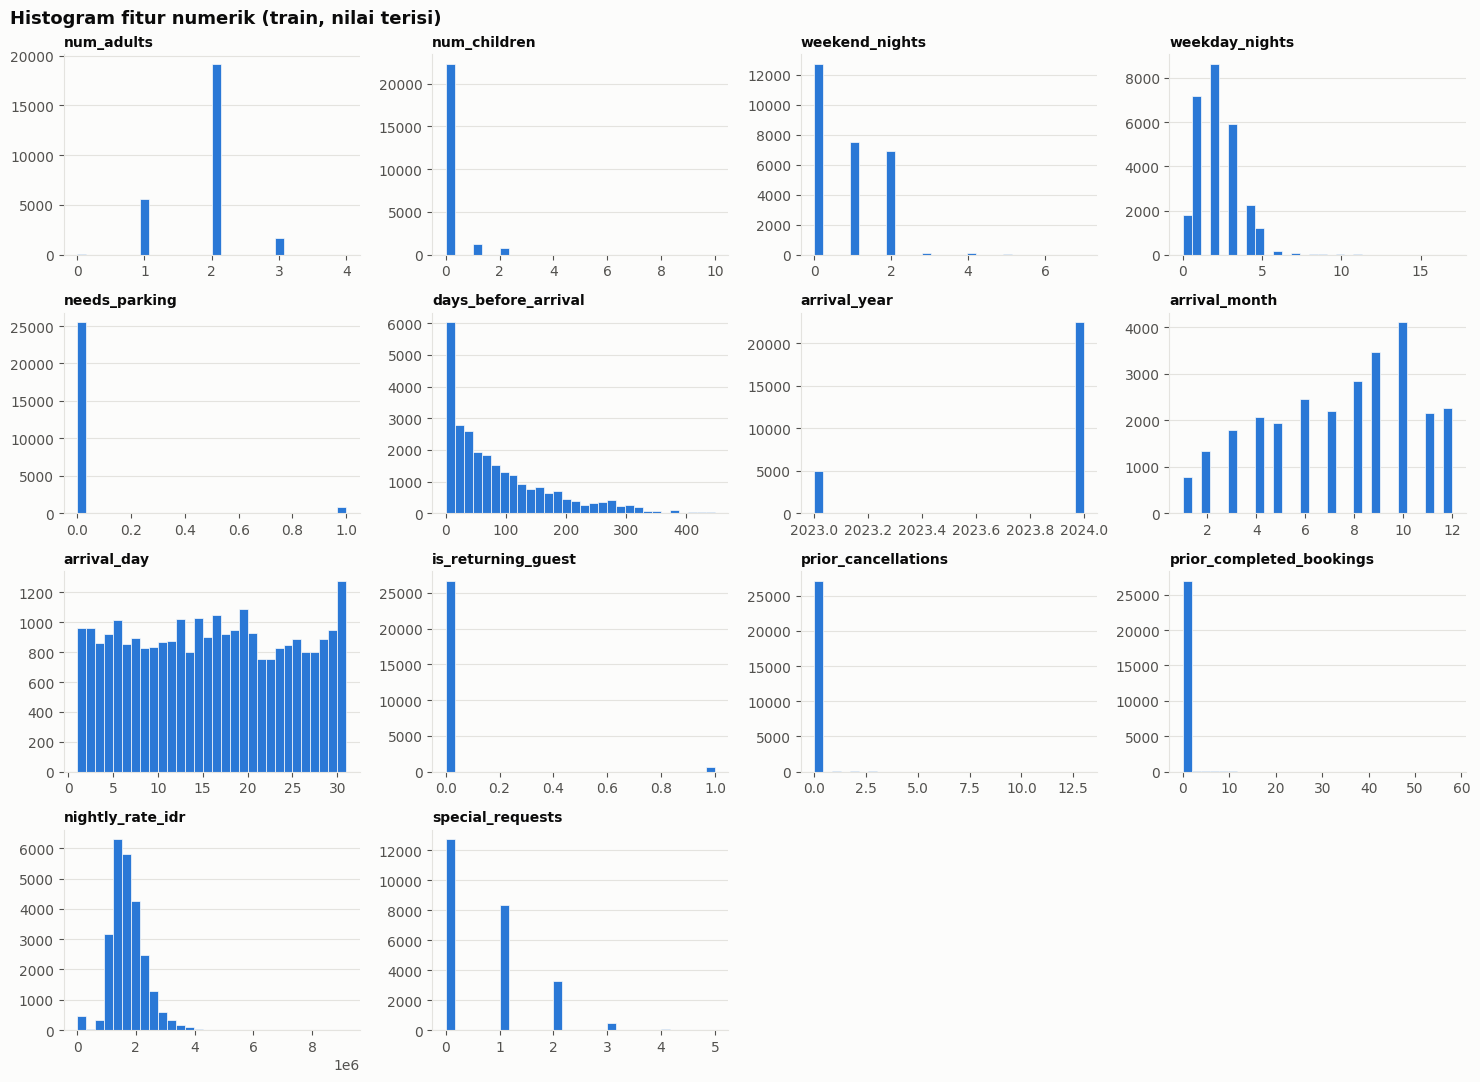

Disimpan: output/figures/eda_numeric_histograms.png


In [12]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, col in zip(axes.ravel(), NUMERICAL_COLS):
    ax.hist(X_raw[col].dropna(), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(NUMERICAL_COLS):]:
    ax.set_visible(False)
fig.suptitle("Histogram fitur numerik (train, nilai terisi)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "eda_numeric_histograms")

## Explore Data

This part covers distributions and relationships between attributes.

### Distribusi target

             jumlah  proporsi
is_canceled                  
0             18404    0.6723
1              8969    0.3277


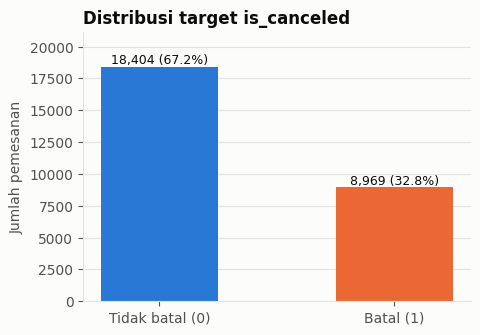

Disimpan: output/figures/eda_target_distribution.png


In [13]:
target_counts = y_raw.value_counts().sort_index()
target_share = y_raw.value_counts(normalize=True).sort_index()
print(pd.DataFrame({"jumlah": target_counts, "proporsi": target_share.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Tidak batal (0)", "Batal (1)"], target_counts.to_numpy(), color=[BLUE, ORANGE], width=0.5)
for bar, share in zip(bars, target_share.to_numpy()):
    ax.annotate(f"{bar.get_height():,.0f} ({share:.1%})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, target_counts.max() * 1.15)
ax.set_ylabel("Jumlah pemesanan")
ax.set_title("Distribusi target is_canceled")
ax.grid(axis="x", visible=False)
save_fig(fig, "eda_target_distribution")

### Distribusi kategori

In [14]:
for col in CATEGORICAL_COLS:
    print(f"--- {col}")
    print(pd.DataFrame({
        "train": X_raw[col].value_counts(dropna=False),
        "test": X_test_raw[col].value_counts(dropna=False),
    }).fillna(0).astype(int))

--- meal_package
              train  test
meal_package             
Breakfast     19654  4940
Room Only      3713   918
Half Board     2242   543
NaN            1760   442
Full Board        4     1
--- room_category
               train  test
room_category             
Type A           699   192
Type B         20447  5096
Type C           189    47
Type D           514   127
Type E             7     0
Type F           119    25
Type G          4396  1115
NaN             1002   242
--- booking_channel
                     train  test
booking_channel                 
Online Travel Agent  17511  4363
Offline Agent         7960  1982
Corporate             1513   394
Complimentary          301    72
Airline                 88    33


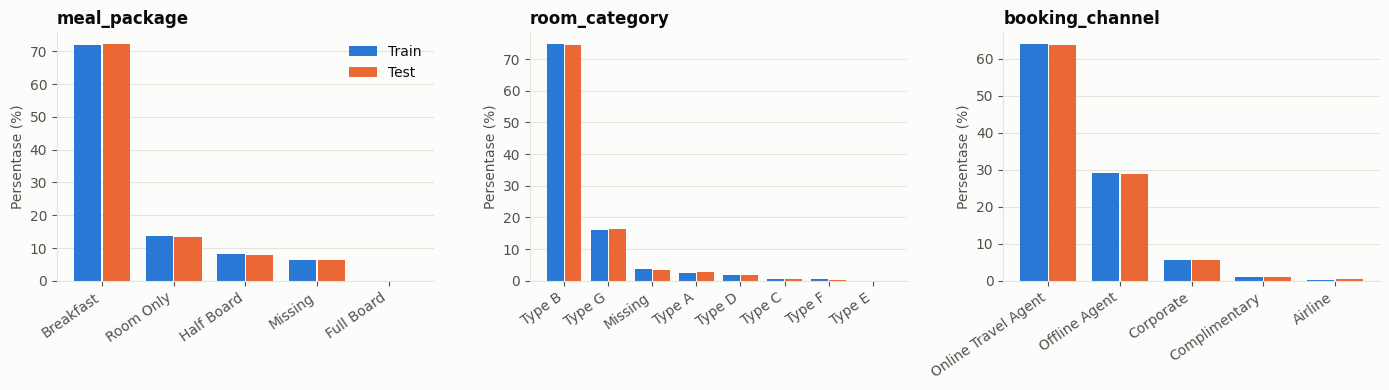

Disimpan: output/figures/eda_categorical_distribution.png


In [15]:
fig, axes = plt.subplots(1, len(CATEGORICAL_COLS), figsize=(14, 4))
for ax, col in zip(axes, CATEGORICAL_COLS):
    tr = X_raw[col].fillna("Missing").value_counts(normalize=True)
    te = X_test_raw[col].fillna("Missing").value_counts(normalize=True)
    order = tr.index.tolist() + [c for c in te.index if c not in tr.index]
    pos = np.arange(len(order))
    ax.bar(pos - 0.2, tr.reindex(order).fillna(0) * 100, width=0.38, color=BLUE, label="Train")
    ax.bar(pos + 0.2, te.reindex(order).fillna(0) * 100, width=0.38, color=ORANGE, label="Test")
    ax.set_xticks(pos, order, rotation=35, ha="right")
    ax.set_title(col)
    ax.set_ylabel("Persentase (%)")
    ax.grid(axis="x", visible=False)
axes[0].legend()
fig.tight_layout()
save_fig(fig, "eda_categorical_distribution")

### Tingkat batal per kategori

Tingkat batal keseluruhan: 32.77%
--- meal_package
             rate      n
Half Board  45.94   2242
Room Only   33.80   3713
Missing     31.93   1760
Breakfast   31.14  19654
Full Board  25.00      4
--- room_category


          rate      n
Type A   42.63    699
Missing  34.83   1002
Type G   34.19   4396
Type D   32.88    514
Type B   32.14  20447
Type E   28.57      7
Type C   24.87    189
Type F   24.37    119
--- booking_channel


                      rate      n
Online Travel Agent  36.37  17511
Airline              30.68     88
Offline Agent        30.15   7960
Corporate            11.50   1513
Complimentary         0.00    301


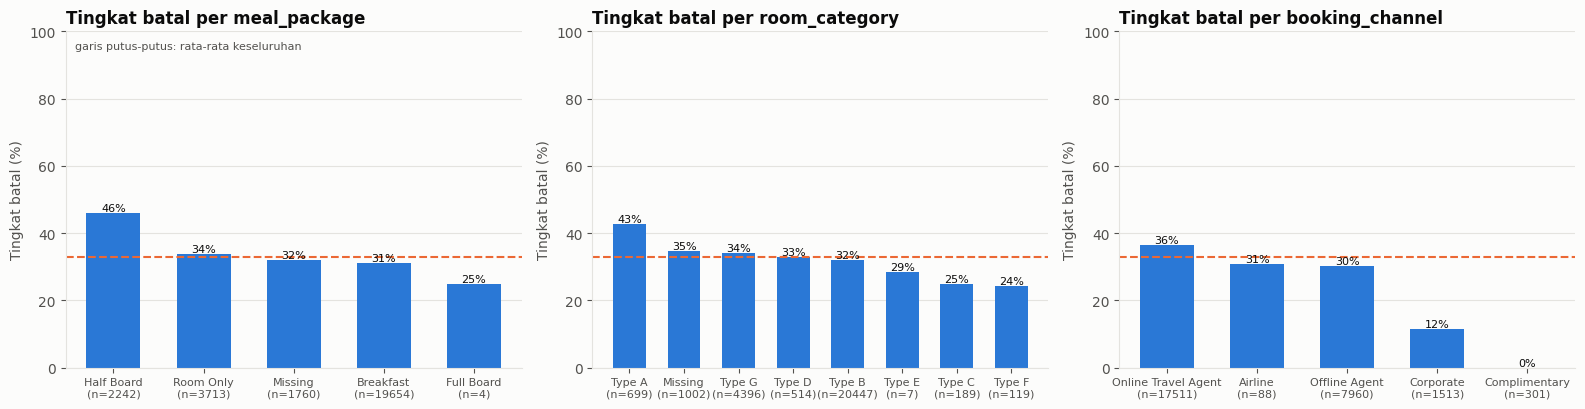

Disimpan: output/figures/eda_cancel_rate_by_category.png


In [16]:
base_rate = y_raw.mean()


def rate_table(feature, numeric=False):
    def label(v):
        if pd.isna(v):
            return "Missing"
        if isinstance(v, (int, float, np.integer, np.floating)) and float(v).is_integer():
            return str(int(v))
        return str(v)

    keys = X_raw[feature].map(label).to_numpy()
    table = y_raw.groupby(keys).agg(rate="mean", n="size")
    if numeric:
        order = sorted(table.index, key=lambda k: (k == "Missing", float(k) if k != "Missing" else 0.0))
        return table.loc[order]
    return table.sort_values("rate", ascending=False)


def plot_rates(ax, table, title):
    pos = np.arange(len(table))
    ax.bar(pos, table["rate"] * 100, width=0.6, color=BLUE)
    ax.axhline(base_rate * 100, color=ORANGE, linewidth=1.5, linestyle="--")
    for p, (rate, n) in enumerate(zip(table["rate"], table["n"])):
        ax.annotate(f"{rate:.0%}", (p, rate * 100), ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(pos, [f"{k}\n(n={n})" for k, n in zip(table.index, table["n"])], fontsize=8)
    ax.set_ylim(0, max(100, table["rate"].max() * 100 * 1.15))
    ax.set_ylabel("Tingkat batal (%)")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)


print(f"Tingkat batal keseluruhan: {base_rate:.2%}")
for col in CATEGORICAL_COLS:
    print(f"--- {col}")
    print(rate_table(col).assign(rate=lambda t: (t.rate * 100).round(2)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, CATEGORICAL_COLS):
    plot_rates(ax, rate_table(col), f"Tingkat batal per {col}")
axes[0].annotate("garis putus-putus: rata-rata keseluruhan", (0.02, 0.97), xycoords="axes fraction",
                 fontsize=8, color=MUTED, va="top")
fig.tight_layout()
save_fig(fig, "eda_cancel_rate_by_category")

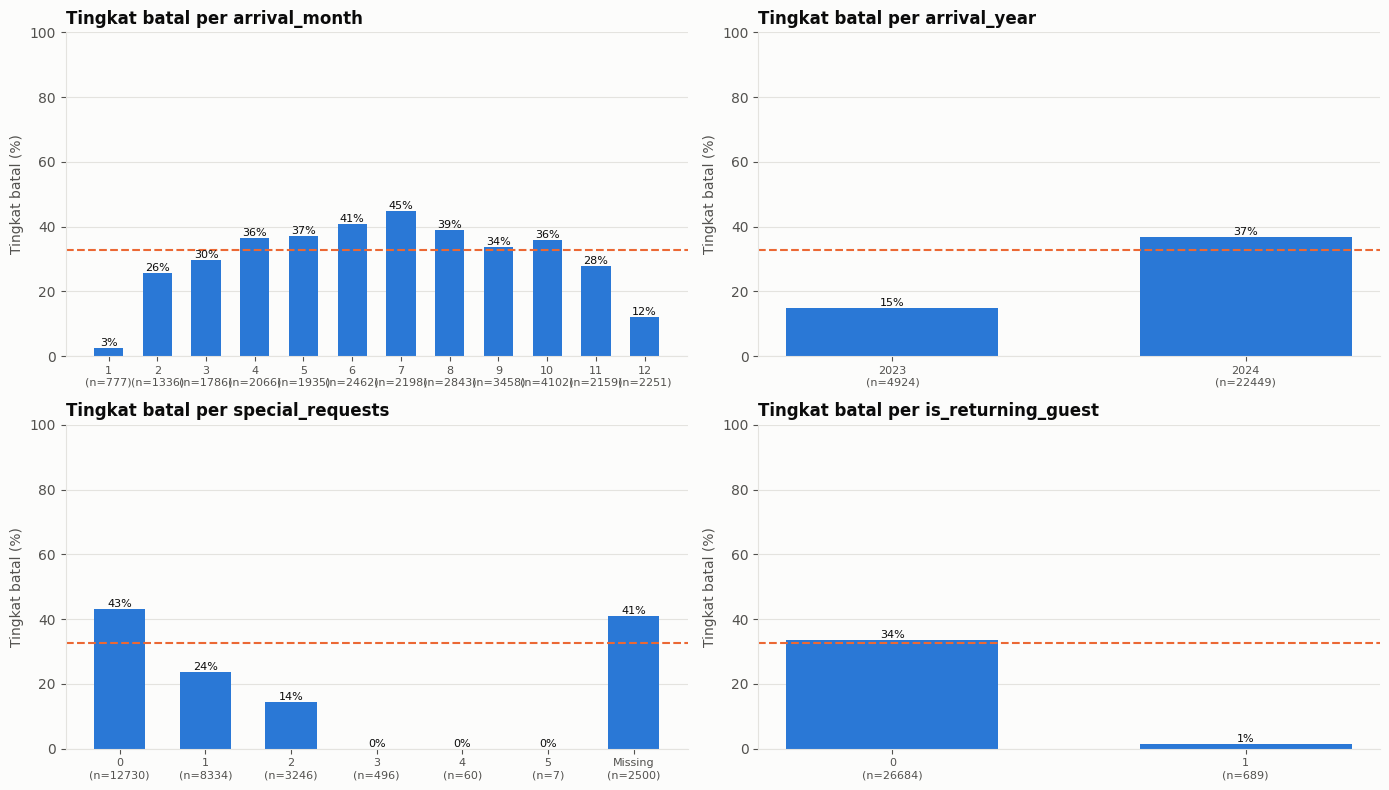

Disimpan: output/figures/eda_cancel_rate_by_discrete_features.png


In [17]:
discrete = ["arrival_month", "arrival_year", "special_requests", "is_returning_guest"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), discrete):
    plot_rates(ax, rate_table(col, numeric=True), f"Tingkat batal per {col}")
fig.tight_layout()
save_fig(fig, "eda_cancel_rate_by_discrete_features")

### Korelasi fitur numerik dengan target

days_before_arrival         0.4403
special_requests           -0.2580
arrival_year                0.1798
nightly_rate_idr            0.1341
is_returning_guest         -0.1072
weekday_nights              0.0972
num_adults                  0.0884
needs_parking              -0.0855
weekend_nights              0.0608
prior_completed_bookings   -0.0589
prior_cancellations        -0.0350
num_children                0.0309
arrival_day                 0.0200
arrival_month              -0.0159
Name: is_canceled, dtype: float64


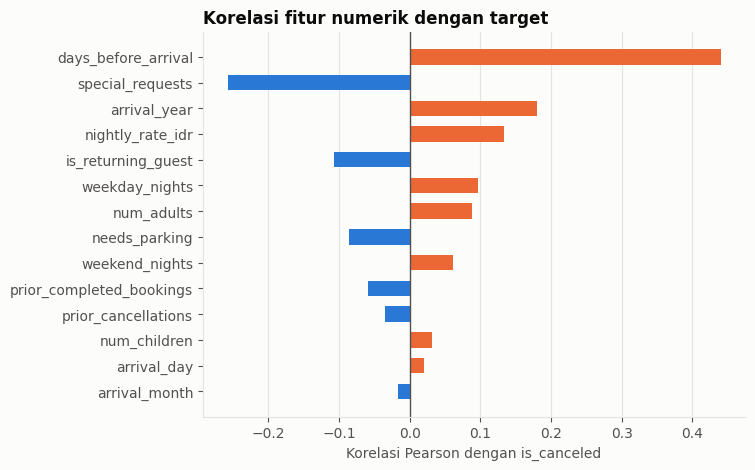

Disimpan: output/figures/eda_numeric_correlation_with_target.png


In [18]:
corr = pd.concat([X_raw[NUMERICAL_COLS], y_raw], axis=1).corr()[config.TARGET_COL].drop(config.TARGET_COL)
corr = corr.reindex(corr.abs().sort_values().index)
print(corr.sort_values(key=abs, ascending=False).round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.to_numpy(), height=0.6, color=[ORANGE if v > 0 else BLUE for v in corr])
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Korelasi Pearson dengan is_canceled")
ax.set_title("Korelasi fitur numerik dengan target")
ax.grid(axis="y", visible=False)
save_fig(fig, "eda_numeric_correlation_with_target")

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

### Missing values per kolom (train vs test)

In [19]:
missing = pd.DataFrame(
    {
        "train_n": X_raw.isna().sum(),
        "train_pct": (X_raw.isna().mean() * 100).round(2),
        "test_n": X_test_raw.isna().sum(),
        "test_pct": (X_test_raw.isna().mean() * 100).round(2),
    }
)
print(f"Kolom dengan missing: {(missing.train_n > 0).sum()} dari {len(missing)}")
missing[(missing.train_n > 0) | (missing.test_n > 0)].sort_values("train_pct", ascending=False)

Kolom dengan missing: 8 dari 17


,train_n,train_pct,test_n,test_pct
num_children,3035,11.09,747,10.91
special_requests,2500,9.13,593,8.66
nightly_rate_idr,2038,7.45,540,7.89
meal_package,1760,6.43,442,6.46
days_before_arrival,1123,4.10,290,4.24
needs_parking,1082,3.95,247,3.61
room_category,1002,3.66,242,3.54
num_adults,809,2.96,180,2.63


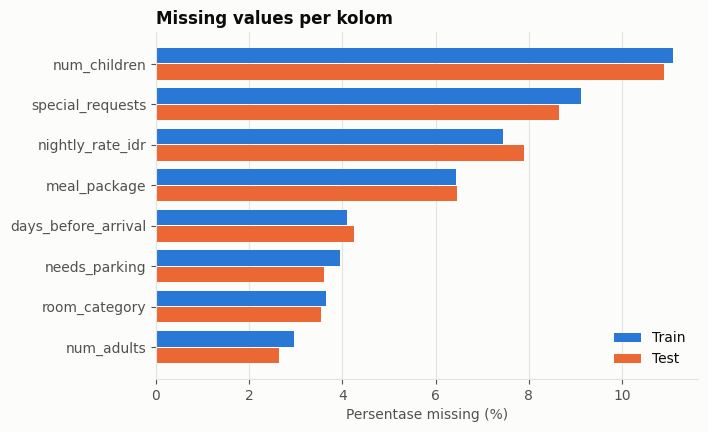

Disimpan: output/figures/eda_missing_values_train_vs_test.png


In [20]:
with_missing = missing[(missing.train_n > 0) | (missing.test_n > 0)].sort_values("train_pct")
pos = np.arange(len(with_missing))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(pos + 0.2, with_missing["train_pct"], height=0.38, color=BLUE, label="Train")
ax.barh(pos - 0.2, with_missing["test_pct"], height=0.38, color=ORANGE, label="Test")
ax.set_yticks(pos, with_missing.index)
ax.set_xlabel("Persentase missing (%)")
ax.set_title("Missing values per kolom")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_fig(fig, "eda_missing_values_train_vs_test")

### Tingkat batal saat kolom kosong vs terisi

In [21]:
rows = []
for col in X_raw.columns[X_raw.isna().any()]:
    is_missing = X_raw[col].isna()
    rows.append(
        {
            "kolom": col,
            "n_kosong": int(is_missing.sum()),
            "batal_saat_kosong": y_raw[is_missing].mean(),
            "batal_saat_terisi": y_raw[~is_missing].mean(),
        }
    )
missing_effect = pd.DataFrame(rows).set_index("kolom")
missing_effect["selisih"] = missing_effect["batal_saat_kosong"] - missing_effect["batal_saat_terisi"]
missing_effect.round(4)

,n_kosong,batal_saat_kosong,batal_saat_terisi,selisih
kolom,,,,
num_adults,809,0.3350,0.3274,0.0075
num_children,3035,0.3282,0.3276,0.0006
meal_package,1760,0.3193,0.3282,-0.0089
needs_parking,1082,0.3124,0.3283,-0.0159
room_category,1002,0.3483,0.3269,0.0214
days_before_arrival,1123,0.3117,0.3283,-0.0167
nightly_rate_idr,2038,0.3131,0.3288,-0.0158
special_requests,2500,0.4084,0.3195,0.0889


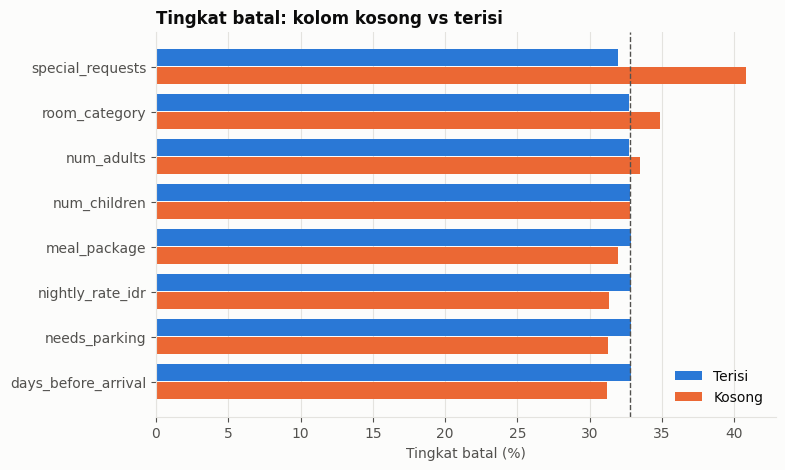

Disimpan: output/figures/eda_cancel_rate_missing_vs_filled.png


In [22]:
plot_df = missing_effect.sort_values("selisih")
pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pos + 0.2, plot_df["batal_saat_terisi"] * 100, height=0.38, color=BLUE, label="Terisi")
ax.barh(pos - 0.2, plot_df["batal_saat_kosong"] * 100, height=0.38, color=ORANGE, label="Kosong")
ax.axvline(base_rate * 100, color=MUTED, linewidth=1, linestyle="--")
ax.set_yticks(pos, plot_df.index)
ax.set_xlabel("Tingkat batal (%)")
ax.set_title("Tingkat batal: kolom kosong vs terisi")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_fig(fig, "eda_cancel_rate_missing_vs_filled")

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [23]:
X_train_raw, X_val, y_train_raw, y_val = sk_train_test_split(
    X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=CFG.SEED
)
train_set = (X_train_raw, y_train_raw)
val_set = (X_val, y_val)

print(f"Train split     : {len(X_train_raw)} baris")
print(f"Validation split: {len(X_val)} baris")
print(pd.DataFrame({
    "train": y_train_raw.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
}).round(4))

Train split     : 21898 baris
Validation split: 5475 baris
              train  validation
is_canceled                    
0            0.6723      0.6723
1            0.3277      0.3277


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [24]:
if False:
    X_selected = X_clean[NUMERICAL_COLS + CATEGORICAL_COLS]
    print(X_selected.shape)

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [25]:
if False:
    indicator = MissingIndicator(NUMERICAL_COLS).fit(X_clean)
    imputer = MissingValueImputer(NUMERICAL_COLS, CATEGORICAL_COLS).fit(X_clean)
    X_imputed = imputer.transform(indicator.transform(X_clean))
    print(int(X_imputed[NUMERICAL_COLS].isna().sum().sum()))

### Duplicates

This part covers repeated records.

In [26]:
X_clean, y_clean = clean_train(X_train_raw, y_train_raw)
print(f"Sebelum cleaning (train split): {len(X_train_raw)} baris")
print(f"Sesudah cleaning (train split): {len(X_clean)} baris")
print(f"Baris dibuang   : {len(X_train_raw) - len(X_clean)}")
print("Distribusi target sesudah cleaning:")
print(y_clean.value_counts().sort_index().to_string())

Sebelum cleaning (train split): 21898 baris
Sesudah cleaning (train split): 21858 baris
Baris dibuang   : 40
Distribusi target sesudah cleaning:
is_canceled
0    14696
1     7162


### Outliers

This part covers values far from the rest of the data.

In [27]:
if False:
    clipper = OutlierClipper(["nightly_rate_idr", "days_before_arrival"], upper_quantile=0.99).fit(X_clean)
    X_clipped = clipper.transform(X_clean)

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

Rows with zero guests (`num_adults + num_children == 0`) are impossible values. They are removed together with the duplicates by `clean_train` in the Duplicates part above.

In [28]:
if False:
    guests = X_clean["num_adults"] + X_clean["num_children"]
    print(int((guests == 0).sum()))
    print(X_clean[CATEGORICAL_COLS].nunique())

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [29]:
if False:
    engineer = FeatureEngineer().fit(X_clean)
    X_constructed = engineer.transform(X_clean)
    print(FeatureEngineer.ENGINEERED_COLS)

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [30]:
if False:
    scaler = StandardScaler(NUMERICAL_COLS).fit(X_clean)
    X_scaled = scaler.transform(X_clean)

### Encoding

This part covers the numeric representation of categorical attributes.

In [31]:
if False:
    encoder = OneHotEncoder(CATEGORICAL_COLS).fit(X_clean)
    X_encoded = encoder.transform(X_clean)
    print(encoder.feature_names_)

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

The reduction steps below start from the full numeric feature matrix, fitted on the training split only.

In [32]:
base_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
Xn_train = base_pipeline.fit_transform(X_clean, y_clean)
print(f"Matriks fitur sebelum reduksi: {Xn_train.shape}")

Matriks fitur sebelum reduksi: (21858, 45)


### Pipeline numerik dengan seleksi fitur (select_k=20)

In [33]:
selection_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, select_k=20)
Xs_train = selection_pipeline.fit_transform(X_clean, y_clean)
selector = dict(selection_pipeline.steps)["selector"]

print(f"Sebelum seleksi: {Xn_train.shape[1]} kolom | sesudah seleksi: {Xs_train.shape[1]} kolom")
print("Kolom terpilih:", ", ".join(selector.selected_features_))

scores = pd.Series(selector.scores_).sort_values(ascending=False)
print(f"Kolom lolos filter variansi dan korelasi: {len(scores)}")
print(f"Kolom disingkirkan filter: {sorted(set(Xn_train.columns) - set(scores.index))}")
scores.round(5).to_frame("skor_mutual_info").head(20)

Sebelum seleksi: 45 kolom | sesudah seleksi: 20 kolom
Kolom terpilih: num_adults, weekday_nights, needs_parking, days_before_arrival, arrival_year, arrival_month, is_returning_guest, prior_completed_bookings, nightly_rate_idr, special_requests, total_nights, total_guests, is_free, total_cost, special_requests__was_missing, meal_package__Breakfast, meal_package__Half Board, booking_channel__Complimentary, booking_channel__Corporate, booking_channel__Online Travel Agent
Kolom lolos filter variansi dan korelasi: 44
Kolom disingkirkan filter: ['prior_cancellations']


,skor_mutual_info
days_before_arrival,0.09710
special_requests,0.03709
arrival_year,0.01882
arrival_month,0.01748
nightly_rate_idr,0.01621
total_cost,0.01489
total_nights,0.00934
is_returning_guest,0.00839
prior_completed_bookings,0.00790
booking_channel__Corporate,0.00680


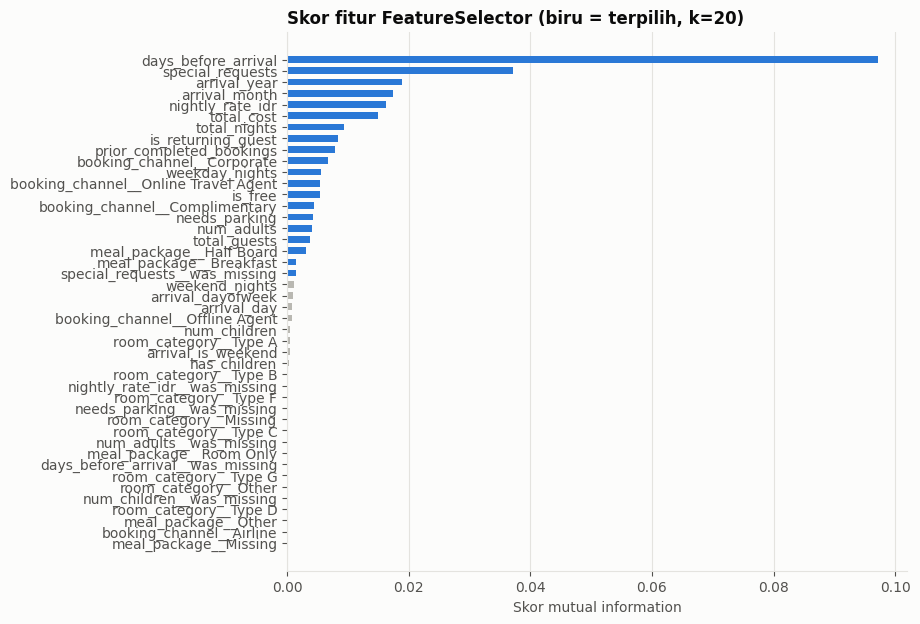

Disimpan: output/figures/prep_feature_selection_scores.png


In [34]:
ranked = scores.sort_values()
chosen = set(selector.selected_features_)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(ranked.index, ranked.to_numpy(), height=0.6, color=[BLUE if c in chosen else NEUTRAL for c in ranked.index])
ax.set_xlabel("Skor mutual information")
ax.set_title("Skor fitur FeatureSelector (biru = terpilih, k=20)")
ax.grid(axis="y", visible=False)
save_fig(fig, "prep_feature_selection_scores")

### PCA

In [35]:
pca_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, use_pca=True)
Xp_train = pca_pipeline.fit_transform(X_clean, y_clean)
Xp_test = pca_pipeline.transform(X_test_raw)
pca_step = dict(pca_pipeline.steps)["pca"]

print(f"Sebelum PCA: {Xn_train.shape[1]} kolom | sesudah PCA (varians 95%): {Xp_train.shape[1]} komponen")
print(f"Total varians terjelaskan: {pca_step.explained_variance_ratio_.sum():.4f}")
print(f"Train: {Xp_train.shape}, Test: {Xp_test.shape}")
Xp_train.head()

Sebelum PCA: 45 kolom | sesudah PCA (varians 95%): 18 komponen
Total varians terjelaskan: 0.9547
Train: (21858, 18), Test: (6844, 18)


,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,pc10,pc11,pc12,pc13,pc14,pc15,pc16,pc17,pc18
0,-0.141435,-0.479692,-0.717729,-1.561947,-0.122043,0.214476,1.459618,2.435155,1.043289,1.369401,2.043654,0.803998,0.022642,-0.927928,-0.380157,-0.759909,-0.252536,-0.134351
1,-0.123488,-0.501150,2.391162,0.313697,-0.588610,0.195233,0.800248,1.960138,-1.160786,1.175389,0.863869,0.897965,0.344269,0.152544,0.013937,1.066352,0.408311,0.002230
2,-2.116802,-0.924996,-0.723543,-1.089813,-2.287694,0.332640,-1.455461,1.084398,-1.020454,0.611900,-0.125378,-0.953831,-0.111957,-1.188580,0.215963,0.171288,0.042050,0.274842
3,-1.229666,0.607021,2.099196,0.255347,-0.394276,0.714648,-0.354758,0.344196,-1.579195,-0.117354,-0.303600,0.422299,0.459027,1.560773,0.552837,-0.232869,0.292817,0.110969
4,0.495376,-0.142790,0.131498,-0.269565,0.907393,-0.579235,-0.703572,-0.061528,-0.902539,-0.657113,-0.973199,-1.189855,0.711271,-0.057358,-0.159567,0.227529,0.746123,0.047271


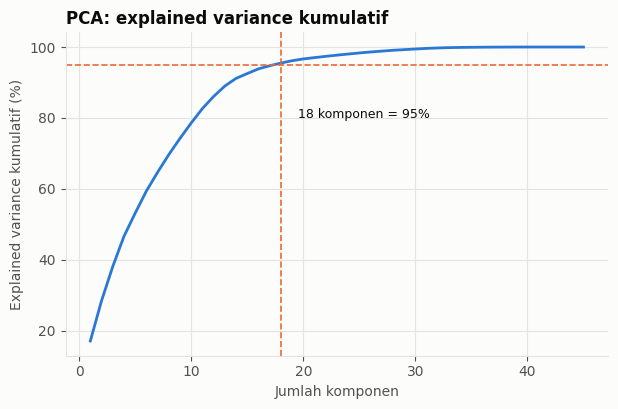

Disimpan: output/figures/prep_pca_cumulative_variance.png


In [36]:
full_pca = PCA(n_components=None).fit(Xn_train)
cumulative = np.cumsum(full_pca.explained_variance_ratio_)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative * 100, color=BLUE)
ax.axhline(95, color=ORANGE, linewidth=1.2, linestyle="--")
ax.axvline(n95, color=ORANGE, linewidth=1.2, linestyle="--")
ax.annotate(f"{n95} komponen = 95%", (n95, 95), xytext=(n95 + 1.5, 80), fontsize=9, color=INK)
ax.set_xlabel("Jumlah komponen")
ax.set_ylabel("Explained variance kumulatif (%)")
ax.set_title("PCA: explained variance kumulatif")
save_fig(fig, "prep_pca_cumulative_variance")

## Class Balance

This part covers the proportion of each class in the training data.

### Resampling (hanya untuk data train)

In [37]:
A = Xn_train.to_numpy(dtype=float)
b = y_clean.to_numpy()

resamplers = {
    "Tanpa resampling": None,
    "RandomUnderSampler": RandomUnderSampler(sampling_strategy=1.0),
    "RandomOverSampler": RandomOverSampler(sampling_strategy=1.0),
    "SMOTE": SMOTE(sampling_strategy=1.0, k_neighbors=5),
}
rows = {}
for name, resampler in resamplers.items():
    if resampler is None:
        A_res, b_res = A, b
    else:
        A_res, b_res = resampler.fit_resample(A, b)
    counts = np.bincount(b_res.astype(int), minlength=2)
    rows[name] = {"kelas_0": int(counts[0]), "kelas_1": int(counts[1]), "total": len(b_res),
                  "n_kolom": A_res.shape[1], "rasio_1:0": round(counts[1] / counts[0], 3)}
resample_table = pd.DataFrame(rows).T
resample_table

,kelas_0,kelas_1,total,n_kolom,rasio_1:0
Tanpa resampling,14696.0,7162.0,21858.0,45.0,0.487
RandomUnderSampler,7162.0,7162.0,14324.0,45.0,1.000
RandomOverSampler,14696.0,14696.0,29392.0,45.0,1.000
SMOTE,14696.0,14696.0,29392.0,45.0,1.000


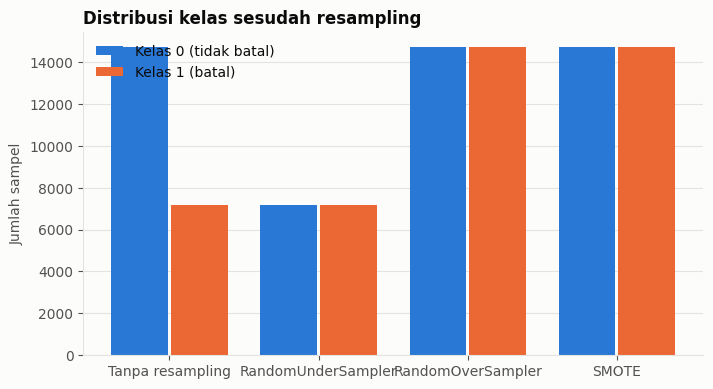

Disimpan: output/figures/prep_resampling_class_distribution.png


In [38]:
pos = np.arange(len(resample_table))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(pos - 0.2, resample_table["kelas_0"], width=0.38, color=BLUE, label="Kelas 0 (tidak batal)")
ax.bar(pos + 0.2, resample_table["kelas_1"], width=0.38, color=ORANGE, label="Kelas 1 (batal)")
ax.set_xticks(pos, resample_table.index)
ax.set_ylabel("Jumlah sampel")
ax.set_title("Distribusi kelas sesudah resampling")
ax.grid(axis="x", visible=False)
ax.legend()
save_fig(fig, "prep_resampling_class_distribution")

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [39]:
if False:
    formatter = TreeInputFormatter(NUMERICAL_COLS, CATEGORICAL_COLS).fit(X_clean)
    X_formatted = formatter.transform(X_clean)
    X_matrix, cat_idx = to_model_input(X_formatted, CATEGORICAL_COLS)
    print(X_matrix.shape, X_matrix.dtype, cat_idx)

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

### Pipeline numerik (KNN, Logistic Regression, SVM)

Pipeline di-fit **hanya** pada data train, lalu `transform` dipakai untuk data test.

In [40]:
numeric_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
print("Langkah:", [name for name, _ in numeric_pipeline.steps])

Xn_train = numeric_pipeline.fit_transform(X_clean, y_clean)
Xn_test = numeric_pipeline.transform(X_test_raw)

print(f"Train: {Xn_train.shape}, Test: {Xn_test.shape}")
print(f"Jumlah kolom: {Xn_train.shape[1]}")
print(", ".join(Xn_train.columns))
print("Kolom train == test:", list(Xn_train.columns) == list(Xn_test.columns))
print("NaN train:", int(Xn_train.isna().sum().sum()), "| NaN test:", int(Xn_test.isna().sum().sum()))
Xn_train.head()

Langkah: ['engineer', 'missing_indicator', 'imputer', 'clipper', 'rare_grouper', 'scaler', 'encoder']
Train: (21858, 45), Test: (6844, 45)
Jumlah kolom: 45
num_adults, num_children, weekend_nights, weekday_nights, needs_parking, days_before_arrival, arrival_year, arrival_month, arrival_day, is_returning_guest, prior_cancellations, prior_completed_bookings, nightly_rate_idr, special_requests, total_nights, total_guests, has_children, is_free, total_cost, arrival_dayofweek, arrival_is_weekend, num_adults__was_missing, num_children__was_missing, needs_parking__was_missing, days_before_arrival__was_missing, nightly_rate_idr__was_missing, special_requests__was_missing, meal_package__Breakfast, meal_package__Half Board, meal_package__Missing, meal_package__Other, meal_package__Room Only, room_category__Missing, room_category__Other, room_category__Type A, room_category__Type B, room_category__Type C, room_category__Type D, room_category__Type F, room_category__Type G, booking_channel__Airlin

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,...,meal_package__Other,meal_package__Room Only,room_category__Missing,room_category__Other,room_category__Type A,room_category__Type B,room_category__Type C,room_category__Type D,room_category__Type F,room_category__Type G,booking_channel__Airline,booking_channel__Complimentary,booking_channel__Corporate,booking_channel__Offline Agent,booking_channel__Online Travel Agent
0,0.290972,-0.265274,1.448772,-1.678739,-0.174233,3.124632,0.468998,0.846503,0.736389,-0.15991,0.0,-0.133831,-0.114747,0.498701,-0.604059,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.290972,-0.265274,0.240559,-0.131714,-0.174233,2.689574,0.468998,1.171492,-1.429609,-0.15991,0.0,-0.133831,-0.382176,-0.774289,0.009516,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.669591,-0.265274,-0.967654,-0.131714,-0.174233,0.997681,-2.132207,0.846503,-1.543608,-0.15991,0.0,-0.133831,-0.164203,-0.774289,-0.604059,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.290972,-0.265274,-0.967654,-0.131714,-0.174233,-0.657957,0.468998,1.496480,-1.657608,-0.15991,0.0,-0.133831,-0.532377,-0.774289,-0.604059,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.290972,-0.265274,-0.967654,0.641798,-0.174233,-0.682127,0.468998,-0.778437,-0.745609,-0.15991,0.0,-0.133831,1.147302,-0.774289,0.009516,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Bukti bahwa statistik hanya dipelajari dari train: parameter hasil fit tidak berubah setelah `transform` test, dan rata-rata test tidak tepat 0.

In [41]:
steps = dict(numeric_pipeline.steps)
imputer_before = dict(steps["imputer"].fill_values_)
scaler_mean_before = dict(steps["scaler"].mean_)

_ = numeric_pipeline.transform(X_test_raw)

print("Parameter imputer tidak berubah:", imputer_before == steps["imputer"].fill_values_)
print("Parameter scaler tidak berubah :", scaler_mean_before == steps["scaler"].mean_)

scaled_cols = list(steps["scaler"].cols)
stats = pd.DataFrame(
    {
        "mean_train": Xn_train[scaled_cols].mean(),
        "mean_test": Xn_test[scaled_cols].mean(),
        "std_train": Xn_train[scaled_cols].std(ddof=0),
        "std_test": Xn_test[scaled_cols].std(ddof=0),
    }
).round(3)
print("Median imputasi nightly_rate_idr (dari train):", imputer_before["nightly_rate_idr"])
stats.head(8)

Parameter imputer tidak berubah: True
Parameter scaler tidak berubah : True
Median imputasi nightly_rate_idr (dari train): 1647000.0


,mean_train,mean_test,std_train,std_test
num_adults,0.0,-0.007,1.0,1.005
num_children,0.0,0.007,1.0,1.022
weekend_nights,0.0,-0.021,1.0,0.993
weekday_nights,-0.0,0.010,1.0,0.989
needs_parking,-0.0,0.017,1.0,1.045
days_before_arrival,-0.0,0.005,1.0,1.005
arrival_year,0.0,-0.004,1.0,1.003
arrival_month,0.0,0.002,1.0,0.991


### Pipeline tree (DTL dan Naive Bayes)

In [42]:
tree_pipeline = make_tree_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
Xt_train = tree_pipeline.fit_transform(X_clean, y_clean)
Xt_test = tree_pipeline.transform(X_test_raw)

print("Langkah:", [name for name, _ in tree_pipeline.steps])
print(f"Train: {Xt_train.shape}, Test: {Xt_test.shape}")
print("Kolom:", ", ".join(Xt_train.columns))

Xt_input, tree_cat_idx = to_model_input(Xt_train, CATEGORICAL_COLS)
print("Input model:", Xt_input.shape, Xt_input.dtype, "| indeks kolom kategorik:", tree_cat_idx)
Xt_train.head()

Langkah: ['engineer', 'rare_grouper', 'formatter']
Train: (21858, 24), Test: (6844, 24)
Kolom: num_adults, num_children, weekend_nights, weekday_nights, needs_parking, days_before_arrival, arrival_year, arrival_month, arrival_day, is_returning_guest, prior_cancellations, prior_completed_bookings, nightly_rate_idr, special_requests, total_nights, total_guests, has_children, is_free, total_cost, arrival_dayofweek, arrival_is_weekend, meal_package, room_category, booking_channel
Input model: (21858, 24) object | indeks kolom kategorik: [21, 22, 23]


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,has_children,is_free,total_cost,arrival_dayofweek,arrival_is_weekend,meal_package,room_category,booking_channel
0,2.0,0.0,2.0,0.0,0.0,388.0,2024.0,10.0,22.0,0.0,0.0,0.0,NaN,1.0,2.0,2.0,0.0,NaN,NaN,1.0,0.0,Half Board,Type B,Offline Agent
1,2.0,0.0,1.0,2.0,0.0,306.0,2024.0,11.0,3.0,0.0,0.0,0.0,1501000.0,NaN,3.0,2.0,0.0,0.0,4503000.0,6.0,1.0,Breakfast,Type B,Online Travel Agent
2,1.0,0.0,0.0,2.0,0.0,166.0,2023.0,10.0,2.0,0.0,0.0,0.0,1620000.0,0.0,2.0,1.0,0.0,0.0,3240000.0,0.0,0.0,Breakfast,Type B,Offline Agent
3,2.0,0.0,0.0,2.0,0.0,29.0,2024.0,12.0,1.0,0.0,0.0,0.0,1419000.0,0.0,2.0,2.0,0.0,0.0,2838000.0,6.0,1.0,Breakfast,Type B,Corporate
4,2.0,0.0,0.0,3.0,0.0,27.0,2024.0,5.0,9.0,0.0,0.0,0.0,2336000.0,NaN,3.0,2.0,0.0,0.0,7008000.0,3.0,0.0,Breakfast,Type B,Online Travel Agent


### Pipeline factories and validation transform

In [43]:
numeric_factory = lambda: make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
tree_factory = lambda: make_tree_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)

X_tr, y_tr = X_clean, y_clean
X_va, y_va = X_val, y_val
A_tr = Xn_train
A_va = numeric_pipeline.transform(X_va)
print(f"Hold-out: train {A_tr.shape}, validasi {A_va.shape}")

Hold-out: train (21858, 45), validasi (5475, 45)


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

Setiap model memiliki dua bagian: implementasi sendiri (kerangka pemakaian, dibungkus `if False:` sampai
`src/models` dan `src/evaluation` diimplementasikan) dan versi scikit-learn yang langsung dijalankan
pada hold-out 20% sebagai pembanding (bagian Comparison with scikit-learn).

### Persiapan bersama

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metrics = {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1_score, "macro_f1": macro_f1}


class ThresholdedModel:
    """Pembungkus tipis: predict memakai threshold pada P(batal) (bukan argmax).

    Dipakai oleh cross_validate (fit, clone, predict) dan make_submission (predict).
    """

    def __init__(self, model, threshold):
        self.model, self.threshold = model, threshold

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def clone(self):
        inner = self.model.clone() if hasattr(self.model, "clone") else sk_clone(self.model)
        return ThresholdedModel(inner, self.threshold)

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict(self, X):
        return (self.model.predict_proba(X)[:, 1] >= self.threshold).astype(int)


def with_threshold(model, threshold):
    """Model apa adanya untuk threshold 0.5 (sama dengan argmax), selain itu dibungkus ThresholdedModel."""
    return model if threshold == 0.5 else ThresholdedModel(model, threshold)


def find_oof_threshold(model, pipeline_factory, X, y, cv):
    """Cari threshold P(batal) yang memaksimalkan macro_f1 pada probabilitas out-of-fold (OOF).

    Tiap fold `cv` (StratifiedKFold): pipeline dibuat ulang lewat pipeline_factory dan di-fit hanya pada
    bagian train fold, model di-clone lalu di-fit, dan P(batal) fold validasi dikumpulkan sebagai OOF.
    Kandidat threshold: semua nilai unik probabilitas OOF ditambah 0.5; prediksi batal jika
    P(batal) >= threshold. Jika skor seri, threshold terkecil yang dipilih.
    """
    y_arr = np.asarray(y).ravel().astype(int)
    oof = np.full(len(y_arr), np.nan)
    for train_idx, val_idx in cv.split(X, y):
        pipeline = pipeline_factory()
        X_fold_tr, _ = to_model_input(pipeline.fit_transform(X.iloc[train_idx], y.iloc[train_idx]), CATEGORICAL_COLS)
        X_fold_va, _ = to_model_input(pipeline.transform(X.iloc[val_idx]), CATEGORICAL_COLS)
        fold_model = model.clone() if hasattr(model, "clone") else sk_clone(model)
        fold_model.fit(X_fold_tr, y_arr[train_idx])
        oof[val_idx] = fold_model.predict_proba(X_fold_va)[:, 1]
    assert not np.isnan(oof).any(), "Ada baris tanpa probabilitas OOF"

    # Macro F1 untuk semua kandidat sekaligus: hitung TP/FP tiap threshold dari probabilitas terurut.
    candidates = np.union1d(np.unique(oof), [0.5])
    pos, neg = np.sort(oof[y_arr == 1]), np.sort(oof[y_arr == 0])
    tp = len(pos) - np.searchsorted(pos, candidates, side="left")
    fp = len(neg) - np.searchsorted(neg, candidates, side="left")
    fn, tn = len(pos) - tp, len(neg) - fp
    with np.errstate(divide="ignore", invalid="ignore"):
        f1_pos = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
        f1_neg = np.where(2 * tn + fp + fn > 0, 2 * tn / (2 * tn + fp + fn), 0.0)
    candidate_scores = (f1_pos + f1_neg) / 2
    best = int(np.argmax(candidate_scores))
    threshold = float(candidates[best])

    # Skor akhir dihitung ulang dengan macro_f1 dari src.evaluation sebagai pemeriksaan.
    oof_macro_f1 = macro_f1(y_arr, (oof >= threshold).astype(int))
    assert np.isclose(oof_macro_f1, candidate_scores[best])
    return {
        "threshold": threshold,
        "oof_macro_f1": oof_macro_f1,
        "oof_macro_f1_at_0_50": macro_f1(y_arr, (oof >= 0.5).astype(int)),
        "n_candidates": len(candidates),
        "oof_proba": oof,
    }

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [45]:
# Konfigurasi terbaik dari output/knn_naivebayes_comparison.csv (baris KNN from-scratch dan scikit-learn identik):
# k=15, weights="distance", metric euclidean, pipeline numerik + PCA (95% varians),
# tanpa resampling, threshold keputusan P(batal) >= 0.45.
KNN_K, KNN_WEIGHTS, KNN_METRIC, KNN_THRESHOLD = 15, "distance", "euclidean", 0.45
KNN_PCA_COMPONENTS = 0.95
knn_factory = lambda: make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, use_pca=True, pca_components=KNN_PCA_COMPONENTS)

knn = KNN(n_neighbors=KNN_K, metric=KNN_METRIC, weights=KNN_WEIGHTS)
knn_model = with_threshold(knn, KNN_THRESHOLD)
print("Parameter:", knn.get_params(), "| threshold:", KNN_THRESHOLD)

knn_cv = cross_validate(knn_model, knn_factory, X_clean, y_clean, cv, metrics)
print("Rata-rata CV 5-fold:", {k: round(float(np.mean(v)), 4) for k, v in knn_cv.items()})
print("Macro F1 per fold  :", np.round(knn_cv["macro_f1"], 4))
print(f"Macro F1 CV        : {np.mean(knn_cv['macro_f1']):.4f} (std {np.std(knn_cv['macro_f1']):.4f})")

# Hold-out 20%: pipeline di-fit pada X_clean, validasi hanya di-transform.
knn_pipeline = knn_factory()
Xk_train, _ = to_model_input(knn_pipeline.fit_transform(X_clean, y_clean), CATEGORICAL_COLS)
Xk_val, _ = to_model_input(knn_pipeline.transform(X_va), CATEGORICAL_COLS)
knn.fit(Xk_train, y_clean.to_numpy())
knn.decision_threshold_ = KNN_THRESHOLD  # ikut tersimpan di pickle model
knn_val_score = knn.predict_proba(Xk_val)[:, 1]
knn_val_pred = knn_model.predict(Xk_val)
knn_holdout_macro_f1 = macro_f1(y_va.to_numpy(), knn_val_pred)
print(f"Fitur setelah PCA  : {Xk_train.shape[1]}")
print(f"Macro F1 hold-out  : {knn_holdout_macro_f1:.4f}")
print(confusion_matrix(y_va.to_numpy(), knn_val_pred))

Parameter: {'n_neighbors': 15, 'metric': 'euclidean', 'p': 2.0, 'weights': 'distance', 'batch_size': 1024, 'random_state': 42} | threshold: 0.45


Rata-rata CV 5-fold: {'accuracy': 0.8353, 'precision': 0.7523, 'recall': 0.7417, 'f1': 0.7469, 'macro_f1': 0.8124}
Macro F1 per fold  : [0.8095 0.8167 0.811  0.8122 0.8127]
Macro F1 CV        : 0.8124 (std 0.0024)


Fitur setelah PCA  : 18
Macro F1 hold-out  : 0.8216
[[3244  437]
 [ 425 1369]]


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [46]:
# Hasil tuning DTL (Anggota 3) tidak ditemukan di output/ maupun di notebook,
# sehingga parameter default DecisionTree dipakai (gain_ratio, tanpa batas kedalaman).
dtl = DecisionTree(categorical_features=tree_cat_idx)
print("Parameter:", dtl.get_params())

dtl_cv = cross_validate(dtl, tree_factory, X_clean, y_clean, cv, metrics)
print("Rata-rata CV 5-fold:", {k: round(float(np.mean(v)), 4) for k, v in dtl_cv.items()})
print("Macro F1 per fold  :", np.round(dtl_cv["macro_f1"], 4))
print(f"Macro F1 CV        : {np.mean(dtl_cv['macro_f1']):.4f} (std {np.std(dtl_cv['macro_f1']):.4f})")

# Hold-out 20%: pipeline di-fit pada X_clean (tree_pipeline), validasi hanya di-transform.
dtl.fit(Xt_input, y_clean.to_numpy())
Xt_val, _ = to_model_input(tree_pipeline.transform(X_va), CATEGORICAL_COLS)
dtl_val_pred = dtl.predict(Xt_val)
dtl_holdout_macro_f1 = macro_f1(y_va.to_numpy(), dtl_val_pred)
print(f"Macro F1 hold-out  : {dtl_holdout_macro_f1:.4f}")
print(confusion_matrix(y_va.to_numpy(), dtl_val_pred))
print("Kedalaman:", dtl.get_depth(), "| jumlah daun:", dtl.get_n_leaves())

# Visualisasi tree (15 node teratas untuk PNG, 30 node teratas untuk DOT)
tree_feature_names = list(Xt_train.columns)
plot_decision_tree(dtl, config.FIGURE_DIR / "decision_tree.png", top_n=15, feature_names=tree_feature_names)
dtl.export_graph(config.FIGURE_DIR / "decision_tree.dot", top_n=30, feature_names=tree_feature_names)
print("Disimpan:", (config.FIGURE_DIR / "decision_tree.png").relative_to(config.ROOT_DIR))
print("Disimpan:", (config.FIGURE_DIR / "decision_tree.dot").relative_to(config.ROOT_DIR))

Parameter: {'criterion': 'gain_ratio', 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'min_gain': 0.0, 'categorical_features': [21, 22, 23], 'random_state': 42}


Rata-rata CV 5-fold: {'accuracy': 0.8447, 'precision': 0.785, 'recall': 0.7248, 'f1': 0.7537, 'macro_f1': 0.8201}
Macro F1 per fold  : [0.8185 0.8236 0.8128 0.826  0.8199]
Macro F1 CV        : 0.8201 (std 0.0045)


Macro F1 hold-out  : 0.8261
[[3356  325]
 [ 493 1301]]
Kedalaman: 71 | jumlah daun: 1280
Disimpan: output/figures/decision_tree.png
Disimpan: output/figures/decision_tree.dot


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [47]:
if False:
    lr = LogisticRegression(penalty="l2", reg_lambda=0.01, learning_rate=0.1, n_iter=1000, batch_size=256)
    lr_cv = cross_validate(lr, numeric_factory, X_clean, y_clean, cv, metrics)
    lr_smote_cv = cross_validate(lr, numeric_factory, X_clean, y_clean, cv, metrics, resampler=SMOTE(sampling_strategy=1.0))
    print({k: float(np.mean(v)) for k, v in lr_cv.items()})

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [48]:
if False:
    svm = SVM(kernel="rbf", C=1.0, gamma="scale", max_train_samples=5000)
    svm_cv = cross_validate(svm, numeric_factory, X_clean, y_clean, cv, metrics)
    print({k: float(np.mean(v)) for k, v in svm_cv.items()})

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [49]:
# Konfigurasi terbaik dari output/knn_naivebayes_comparison.csv (baris Naive Bayes from-scratch):
# alpha=0.5, var_smoothing=1e-12, pipeline tree, RandomOverSampler(sampling_strategy=0.75, seed 42)
# hanya pada data train, threshold 0.5 (= argmax, tanpa ThresholdedModel).
NB_ALPHA, NB_VAR_SMOOTHING, NB_THRESHOLD, NB_OVER_STRATEGY = 0.5, 1e-12, 0.5, 0.75
nb_resampler = RandomOverSampler(sampling_strategy=NB_OVER_STRATEGY, random_state=SEED)

nb = NaiveBayes(categorical_features=tree_cat_idx, alpha=NB_ALPHA, var_smoothing=NB_VAR_SMOOTHING)
nb_model = with_threshold(nb, NB_THRESHOLD)
print("Parameter:", nb.get_params(), "| threshold:", NB_THRESHOLD)

nb_cv = cross_validate(nb_model, tree_factory, X_clean, y_clean, cv, metrics, resampler=nb_resampler)
print("Rata-rata CV 5-fold:", {k: round(float(np.mean(v)), 4) for k, v in nb_cv.items()})
print("Macro F1 per fold  :", np.round(nb_cv["macro_f1"], 4))
print(f"Macro F1 CV        : {np.mean(nb_cv['macro_f1']):.4f} (std {np.std(nb_cv['macro_f1']):.4f})")

# Hold-out 20%: pipeline tree di-fit pada X_clean, oversampling hanya pada data train.
Xnb_val, _ = to_model_input(tree_pipeline.transform(X_va), CATEGORICAL_COLS)
Xnb_res, ynb_res = nb_resampler.fit_resample(Xt_input, y_clean.to_numpy())
print(f"Train sebelum/sesudah oversampling: {len(Xt_input)} -> {len(Xnb_res)} baris | kelas 1: {int(ynb_res.sum())}")
nb.fit(Xnb_res, ynb_res)
nb_val_score = nb.predict_proba(Xnb_val)[:, 1]
nb_val_pred = nb_model.predict(Xnb_val)
nb_holdout_macro_f1 = macro_f1(y_va.to_numpy(), nb_val_pred)
print(f"Macro F1 hold-out  : {nb_holdout_macro_f1:.4f}")
print(confusion_matrix(y_va.to_numpy(), nb_val_pred))

Parameter: {'categorical_features': [21, 22, 23], 'alpha': 0.5, 'var_smoothing': 1e-12, 'random_state': 42} | threshold: 0.5


Rata-rata CV 5-fold: {'accuracy': 0.739, 'precision': 0.613, 'recall': 0.5518, 'f1': 0.5807, 'macro_f1': 0.6956}
Macro F1 per fold  : [0.7016 0.6944 0.6978 0.6864 0.698 ]
Macro F1 CV        : 0.6956 (std 0.0052)
Train sebelum/sesudah oversampling: 21858 -> 25718 baris | kelas 1: 11022
Macro F1 hold-out  : 0.6998
[[3040  641]
 [ 778 1016]]


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [50]:
if False:
    best_params, search_log = grid_search(
        KNN(), {"n_neighbors": [5, 15, 25], "weights": ["uniform", "distance"]},
        numeric_factory, X_clean, y_clean, cv, scoring=f1_score,
    )
    print(best_params)

### Cost-Sensitive Learning

Dengan biaya FP = 2 dan FN = 1, threshold optimal Bayes adalah `FP / (FP + FN)` = 2/3: model baru
memprediksi batal jika peluang batal melebihi 2/3. Demonstrasi di bawah memakai skor Logistic Regression scikit-learn.

Cost pada threshold 0.5     : 1515
Cost pada threshold Bayes   : 1380 (t = 0.667)
Cost minimum hasil sweep    : 1375 (t = 0.66)


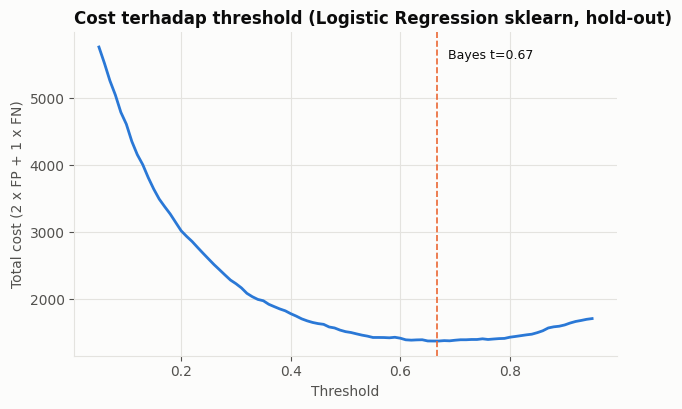

Disimpan: output/figures/cost_threshold_sweep.png


In [51]:
y_true_va = y_va.to_numpy()
cost_lr = SkLogisticRegression(max_iter=1000, random_state=SEED).fit(A_tr, y_tr)
proba = cost_lr.predict_proba(A_va)[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)


def cost_at(threshold):
    pred = (proba >= threshold).astype(int)
    fp = int(((pred == 1) & (y_true_va == 0)).sum())
    fn = int(((pred == 0) & (y_true_va == 1)).sum())
    return config.FP_COST * fp + config.FN_COST * fn


costs = np.array([cost_at(t) for t in thresholds])
best_t = thresholds[int(np.argmin(costs))]
bayes_t = config.FP_COST / (config.FP_COST + config.FN_COST)
print(f"Cost pada threshold 0.5     : {cost_at(0.5):.0f}")
print(f"Cost pada threshold Bayes   : {cost_at(bayes_t):.0f} (t = {bayes_t:.3f})")
print(f"Cost minimum hasil sweep    : {costs.min():.0f} (t = {best_t:.2f})")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(thresholds, costs, color=BLUE)
ax.axvline(bayes_t, color=ORANGE, linewidth=1.2, linestyle="--")
ax.annotate(f"Bayes t={bayes_t:.2f}", (bayes_t, costs.max()), xytext=(bayes_t + 0.02, costs.max() * 0.97), fontsize=9)
ax.set_xlabel("Threshold")
ax.set_ylabel("Total cost (2 x FP + 1 x FN)")
ax.set_title("Cost terhadap threshold (Logistic Regression sklearn, hold-out)")
save_fig(fig, "cost_threshold_sweep")

In [52]:
if False:
    print("Threshold Bayes:", bayes_optimal_threshold(config.FP_COST, config.FN_COST))
    print("Class weight:", cost_sensitive_class_weight(config.FP_COST, config.FN_COST))

    lr_cost = LogisticRegression(class_weight=cost_sensitive_class_weight(config.FP_COST, config.FN_COST))
    cost_pipeline = numeric_factory()
    A_cost_tr, _ = to_model_input(cost_pipeline.fit_transform(X_tr, y_tr), CATEGORICAL_COLS)
    A_cost_va, _ = to_model_input(cost_pipeline.transform(X_va), CATEGORICAL_COLS)
    lr_cost.fit(A_cost_tr, y_tr.to_numpy())

    scores_va = lr_cost.predict_proba(A_cost_va)[:, 1]
    tuned_t = tune_threshold(y_va.to_numpy(), scores_va, config.FP_COST, config.FN_COST)
    y_pred_tuned = (scores_va >= tuned_t).astype(int)
    print("Threshold hasil tuning:", tuned_t)
    print("Cost:", misclassification_cost(y_va.to_numpy(), y_pred_tuned, config.FP_COST, config.FN_COST))
    print(confusion_matrix(y_va.to_numpy(), y_pred_tuned))
    print(classification_report(y_va.to_numpy(), y_pred_tuned))
    print("ROC AUC:", roc_auc(y_va.to_numpy(), scores_va))

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [53]:
def sk_evaluate(y_true, y_pred, y_score=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": sk_f1(y_true, y_pred),
        "macro_f1": macro_f1(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
        "cost": config.FP_COST * fp + config.FN_COST * fn,
    }


sk_results = {}
sk_scores = {}

### K-Nearest Neighbors (KNN)

In [54]:
# Konfigurasi terbaik KNN scikit-learn (baris KNN scikit-learn di CSV): sama dengan KNN sendiri, yaitu
# k=15, weights="distance", pipeline numerik + PCA 95%, tanpa resampling, threshold P(batal) >= 0.45.
sk_knn = KNeighborsClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
sk_knn_model = with_threshold(sk_knn, KNN_THRESHOLD)
sk_knn_cv = cross_validate(sk_knn_model, knn_factory, X_clean, y_clean, cv, metrics)

sk_knn.fit(Xk_train, y_clean.to_numpy())
sk_scores["KNN"] = sk_knn.predict_proba(Xk_val)[:, 1]
sk_results["KNN"] = sk_evaluate(y_va, sk_knn_model.predict(Xk_val), sk_scores["KNN"])
print(f"Macro F1 CV 5-fold: {np.mean(sk_knn_cv['macro_f1']):.4f} (std {np.std(sk_knn_cv['macro_f1']):.4f})")
pd.Series(sk_results["KNN"]).round(4)

Macro F1 CV 5-fold: 0.8124 (std 0.0024)


accuracy        0.8426
precision       0.7580
recall          0.7631
f1              0.7606
macro_f1        0.8216
roc_auc         0.9134
cost         1299.0000
dtype: float64

### Decision Tree Learning (DTL)

In [55]:
# Parameter disamakan dengan DecisionTree sendiri (default): entropy, tanpa batas kedalaman.
sk_dt = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(A_tr, y_tr)
sk_scores["DTL"] = sk_dt.predict_proba(A_va)[:, 1]
sk_results["DTL"] = sk_evaluate(y_va, sk_dt.predict(A_va), sk_scores["DTL"])

sk_dt_cv = cross_validate(
    DecisionTreeClassifier(criterion="entropy", random_state=SEED),
    numeric_factory, X_clean, y_clean, cv, metrics,
)
pd.Series(sk_results["DTL"]).round(4)

accuracy        0.8336
precision       0.7383
recall          0.7625
f1              0.7502
macro_f1        0.8127
roc_auc         0.8154
cost         1396.0000
dtype: float64

#### Perbandingan DTL: implementasi sendiri vs scikit-learn

Macro F1 adalah metrik Kaggle. Model sendiri memakai pipeline tree (C4.5 dengan pruning), scikit-learn memakai pipeline numerik.

In [56]:
dtl_comparison = pd.DataFrame(
    {
        "DTL sendiri (C4.5)": {
            "cv_macro_f1_mean": np.mean(dtl_cv["macro_f1"]),
            "cv_macro_f1_std": np.std(dtl_cv["macro_f1"]),
            "holdout_macro_f1": dtl_holdout_macro_f1,
            "kedalaman": dtl.get_depth(),
            "jumlah_daun": dtl.get_n_leaves(),
        },
        "DTL scikit-learn": {
            "cv_macro_f1_mean": np.mean(sk_dt_cv["macro_f1"]),
            "cv_macro_f1_std": np.std(sk_dt_cv["macro_f1"]),
            "holdout_macro_f1": sk_results["DTL"]["macro_f1"],
            "kedalaman": sk_dt.get_depth(),
            "jumlah_daun": sk_dt.get_n_leaves(),
        },
    }
).T
dtl_comparison.round(4)

,cv_macro_f1_mean,cv_macro_f1_std,holdout_macro_f1,kedalaman,jumlah_daun
DTL sendiri (C4.5),0.8201,0.0045,0.8261,71.0,1280.0
DTL scikit-learn,0.8025,0.0093,0.8127,35.0,2546.0


### Logistic Regression

In [57]:
sk_lr = SkLogisticRegression(max_iter=1000, random_state=SEED).fit(A_tr, y_tr)
sk_scores["Logistic Regression"] = sk_lr.predict_proba(A_va)[:, 1]
sk_results["Logistic Regression"] = sk_evaluate(y_va, sk_lr.predict(A_va), sk_scores["Logistic Regression"])
pd.Series(sk_results["Logistic Regression"]).round(4)

accuracy        0.7985
precision       0.7281
recall          0.6148
f1              0.6667
macro_f1        0.7612
roc_auc         0.8556
cost         1515.0000
dtype: float64

### Support Vector Machine (SVM)

In [58]:
sk_svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(A_tr, y_tr)
sk_scores["SVM"] = sk_svm.decision_function(A_va)
sk_results["SVM"] = sk_evaluate(y_va, sk_svm.predict(A_va), sk_scores["SVM"])
pd.Series(sk_results["SVM"]).round(4)

accuracy        0.8323
precision       0.7988
recall          0.6527
f1              0.7184
macro_f1        0.7995
roc_auc         0.8871
cost         1213.0000
dtype: float64

### Naive Bayes

In [59]:
# Konfigurasi Naive Bayes scikit-learn (baris Naive Bayes scikit-learn di CSV, berbeda dari model sendiri):
# GaussianNB(var_smoothing=1e-6), pipeline numerik, tanpa resampling.
# Threshold P(batal) tidak di-hardcode: dicari dengan find_oof_threshold (5-fold OOF pada X_clean, bukan val_set).
SK_NB_VAR_SMOOTHING = 1e-6
sk_nb = GaussianNB(var_smoothing=SK_NB_VAR_SMOOTHING)
sk_nb_search = find_oof_threshold(sk_nb, numeric_factory, X_clean, y_clean, cv)
SK_NB_THRESHOLD = sk_nb_search["threshold"]

csv_rows = pd.read_csv(config.OUTPUT_DIR / "knn_naivebayes_comparison.csv")
SK_NB_CSV_THRESHOLD = float(
    csv_rows.loc[(csv_rows["model"] == "Naive Bayes") & (csv_rows["implementation"] == "scikit-learn"), "threshold"].iloc[0]
)
sk_nb_oof = sk_nb_search["oof_proba"]
print(f"Kandidat threshold dievaluasi  : {sk_nb_search['n_candidates']}")
print(f"Threshold hasil pencarian OOF  : {SK_NB_THRESHOLD!r}")
print(f"Threshold di CSV               : {SK_NB_CSV_THRESHOLD!r}")
print(f"Selisih (notebook - CSV)       : {SK_NB_THRESHOLD - SK_NB_CSV_THRESHOLD:+.3e}")
print(f"Macro F1 OOF @ threshold notebook: {sk_nb_search['oof_macro_f1']:.4f}")
print(f"Macro F1 OOF @ threshold CSV     : {macro_f1(y_clean.to_numpy(), (sk_nb_oof >= SK_NB_CSV_THRESHOLD).astype(int)):.4f}")
print(f"Macro F1 OOF @ threshold 0.5     : {sk_nb_search['oof_macro_f1_at_0_50']:.4f}")

sk_nb_model = with_threshold(sk_nb, SK_NB_THRESHOLD)
# Catatan: threshold dipilih pada fold yang sama, sehingga CV di bawah sedikit optimistis; hold-out tidak ikut dipakai.
sk_nb_cv = cross_validate(sk_nb_model, numeric_factory, X_clean, y_clean, cv, metrics)

sk_nb.fit(A_tr, y_tr)
sk_scores["Naive Bayes"] = sk_nb.predict_proba(A_va)[:, 1]
sk_results["Naive Bayes"] = sk_evaluate(y_va, sk_nb_model.predict(A_va), sk_scores["Naive Bayes"])
sk_nb_holdout_at_csv = macro_f1(y_va.to_numpy(), (sk_scores["Naive Bayes"] >= SK_NB_CSV_THRESHOLD).astype(int))
print(f"Macro F1 CV 5-fold: {np.mean(sk_nb_cv['macro_f1']):.4f} (std {np.std(sk_nb_cv['macro_f1']):.4f})")
print(f"Macro F1 hold-out : {sk_results['Naive Bayes']['macro_f1']:.4f} (threshold CSV sebagai pembanding: {sk_nb_holdout_at_csv:.4f})")
pd.Series(sk_results["Naive Bayes"]).round(4)

Kandidat threshold dievaluasi  : 21159
Threshold hasil pencarian OOF  : 0.9999990057509343
Threshold di CSV               : 0.9999991084349512
Selisih (notebook - CSV)       : -1.027e-07
Macro F1 OOF @ threshold notebook: 0.6903
Macro F1 OOF @ threshold CSV     : 0.6890
Macro F1 OOF @ threshold 0.5     : 0.3825


Macro F1 CV 5-fold: 0.6864 (std 0.0092)
Macro F1 hold-out : 0.6872 (threshold CSV sebagai pembanding: 0.6848)


accuracy        0.7470
precision       0.6589
recall          0.4727
f1              0.5505
macro_f1        0.6872
roc_auc         0.7786
cost         1824.0000
dtype: float64

### Perbandingan Model

Tabel di bawah memuat hasil scikit-learn pada hold-out 20% (cost = 2 x FP + 1 x FN). Perbandingan model
implementasi sendiri dengan cross-validation diaktifkan setelah modelnya selesai.

In [60]:
comparison_sk = pd.DataFrame(sk_results).T.round(4).sort_values("cost")
comparison_sk

,accuracy,precision,recall,f1,macro_f1,roc_auc,cost
SVM,0.8323,0.7988,0.6527,0.7184,0.7995,0.8871,1213.0
KNN,0.8426,0.7580,0.7631,0.7606,0.8216,0.9134,1299.0
DTL,0.8336,0.7383,0.7625,0.7502,0.8127,0.8154,1396.0
Logistic Regression,0.7985,0.7281,0.6148,0.6667,0.7612,0.8556,1515.0
Naive Bayes,0.7470,0.6589,0.4727,0.5505,0.6872,0.7786,1824.0


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

Tabel dan grafik di bawah membandingkan Macro F1 (metrik Kaggle) semua model yang aktif, versi sendiri dan
scikit-learn: rata-rata 5-fold `StratifiedKFold` pada train split (`cross_validate`) dan skor hold-out pada `val_set`.
Bagian ini ditempatkan sesudah pembanding scikit-learn karena membutuhkan hasilnya. Logistic Regression dan SVM
belum aktif; cukup mengaktifkan blok `if False:` di bawah setelah modelnya dijalankan, lalu tabel dan grafik ikut terisi.

In [61]:
eval_rows = []


def add_eval_row(model, implementation, cv_macro_f1, holdout_macro_f1):
    """Satu baris tabel evaluasi: Macro F1 CV (mean, std) dan hold-out."""
    eval_rows.append(
        {
            "model": model,
            "implementasi": implementation,
            "cv_macro_f1_mean": float(np.mean(cv_macro_f1)),
            "cv_macro_f1_std": float(np.std(cv_macro_f1)),
            "holdout_macro_f1": float(holdout_macro_f1),
        }
    )


add_eval_row("KNN", "sendiri", knn_cv["macro_f1"], knn_holdout_macro_f1)
add_eval_row("KNN", "scikit-learn", sk_knn_cv["macro_f1"], sk_results["KNN"]["macro_f1"])
add_eval_row("Naive Bayes", "sendiri", nb_cv["macro_f1"], nb_holdout_macro_f1)
add_eval_row("Naive Bayes", "scikit-learn", sk_nb_cv["macro_f1"], sk_results["Naive Bayes"]["macro_f1"])
add_eval_row("Decision Tree", "sendiri", dtl_cv["macro_f1"], dtl_holdout_macro_f1)
add_eval_row("Decision Tree", "scikit-learn", sk_dt_cv["macro_f1"], sk_results["DTL"]["macro_f1"])

# Belum aktif: butuh lr_cv, lr_holdout_macro_f1, svm_cv, svm_holdout_macro_f1 (bagian modeling sendiri)
# dan sk_lr_cv, sk_svm_cv (cross_validate untuk SkLogisticRegression dan SVC di bagian scikit-learn).
if False:
    add_eval_row("Logistic Regression", "sendiri", lr_cv["macro_f1"], lr_holdout_macro_f1)
    add_eval_row("Logistic Regression", "scikit-learn", sk_lr_cv["macro_f1"], sk_results["Logistic Regression"]["macro_f1"])
    add_eval_row("SVM", "sendiri", svm_cv["macro_f1"], svm_holdout_macro_f1)
    add_eval_row("SVM", "scikit-learn", sk_svm_cv["macro_f1"], sk_results["SVM"]["macro_f1"])

evaluation_table = pd.DataFrame(eval_rows).set_index(["model", "implementasi"])
evaluation_table.round(4)

cv_macro_f1_mean  cv_macro_f1_std  holdout_macro_f1
model         implementasi                                                     
KNN           sendiri                 0.8124           0.0024            0.8216
              scikit-learn            0.8124           0.0024            0.8216
Naive Bayes   sendiri                 0.6956           0.0052            0.6998
              scikit-learn            0.6864           0.0092            0.6872
Decision Tree sendiri                 0.8201           0.0045            0.8261
              scikit-learn            0.8025           0.0093            0.8127

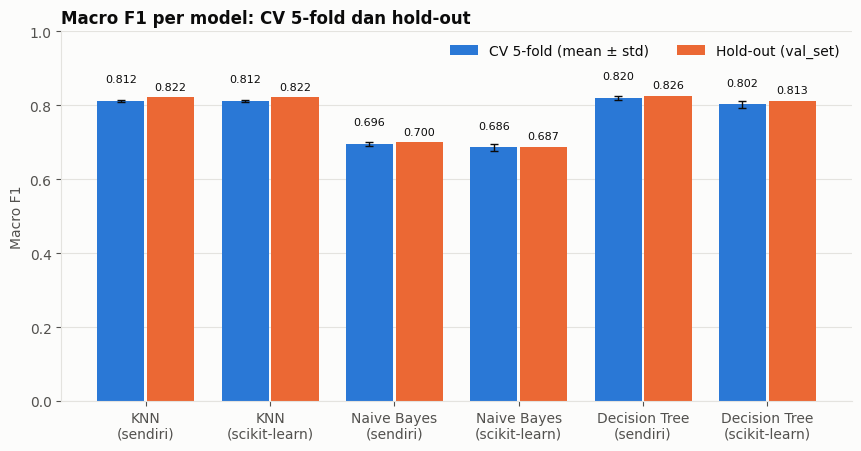

Disimpan: output/figures/model_evaluation_macro_f1.png


In [62]:
labels = [f"{m}\n({i})" for m, i in evaluation_table.index]
pos = np.arange(len(evaluation_table))

fig, ax = plt.subplots(figsize=(max(8, 1.7 * len(pos)), 4.8))
cv_bars = ax.bar(pos - 0.2, evaluation_table["cv_macro_f1_mean"], width=0.38, color=BLUE,
                 yerr=evaluation_table["cv_macro_f1_std"], error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3},
                 label="CV 5-fold (mean ± std)")
ho_bars = ax.bar(pos + 0.2, evaluation_table["holdout_macro_f1"], width=0.38, color=ORANGE, label="Hold-out (val_set)")
for bars in (cv_bars, ho_bars):
    for bar in bars:
        ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4 if bars is ho_bars else 12), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(pos, labels)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 per model: CV 5-fold dan hold-out")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2)
save_fig(fig, "model_evaluation_macro_f1")

### Konsistensi dengan `output/knn_naivebayes_comparison.csv`

Selisih threshold, Macro F1 CV, dan Macro F1 hold-out notebook terhadap CSV (notebook − CSV) untuk setiap baris KNN dan
Naive Bayes. Angka tidak disesuaikan; selisih Macro F1 di atas 0.005 hanya ditandai.

In [63]:
reference = pd.read_csv(config.OUTPUT_DIR / "knn_naivebayes_comparison.csv")
impl_map = {"from-scratch": "sendiri", "scikit-learn": "scikit-learn"}
reference["implementasi"] = reference["implementation"].map(impl_map)
reference = reference.set_index(["model", "implementasi"])

notebook_thresholds = {
    ("KNN", "sendiri"): KNN_THRESHOLD,
    ("KNN", "scikit-learn"): KNN_THRESHOLD,
    ("Naive Bayes", "sendiri"): NB_THRESHOLD,
    ("Naive Bayes", "scikit-learn"): SK_NB_THRESHOLD,
}

rows = []
for key in reference.index:
    nb_row, ref = evaluation_table.loc[key], reference.loc[key]
    rows.append(
        {
            "model": key[0],
            "implementasi": key[1],
            "threshold_notebook": notebook_thresholds[key],
            "threshold_csv": ref["threshold"],
            "threshold_selisih": notebook_thresholds[key] - ref["threshold"],
            "cv_notebook": nb_row["cv_macro_f1_mean"],
            "cv_csv": ref["cv_mean_macro_f1"],
            "cv_selisih": nb_row["cv_macro_f1_mean"] - ref["cv_mean_macro_f1"],
            "holdout_notebook": nb_row["holdout_macro_f1"],
            "holdout_csv": ref["holdout_macro_f1"],
            "holdout_selisih": nb_row["holdout_macro_f1"] - ref["holdout_macro_f1"],
        }
    )
check = pd.DataFrame(rows).set_index(["model", "implementasi"])
check["lebih_dari_0.005"] = (check[["cv_selisih", "holdout_selisih"]].abs() > 0.005).any(axis=1)

for (model, impl), row in check.iterrows():
    print(
        f"{model} ({impl}): threshold {row['threshold_selisih']:+.3e} | "
        f"CV {row['cv_selisih']:+.4f} | hold-out {row['holdout_selisih']:+.4f}"
        + ("  <- lebih dari 0.005" if row["lebih_dari_0.005"] else "")
    )

formats = {"threshold_notebook": "{:.10g}", "threshold_csv": "{:.10g}", "threshold_selisih": "{:+.3e}",
           "cv_selisih": "{:+.4f}", "holdout_selisih": "{:+.4f}",
           "cv_notebook": "{:.4f}", "cv_csv": "{:.4f}", "holdout_notebook": "{:.4f}", "holdout_csv": "{:.4f}"}
check_display = check.copy()
for col, fmt in formats.items():
    check_display[col] = check[col].map(fmt.format)
check_display

KNN (sendiri): threshold +0.000e+00 | CV -0.0035 | hold-out +0.0000
KNN (scikit-learn): threshold +0.000e+00 | CV -0.0035 | hold-out +0.0000
Naive Bayes (sendiri): threshold +0.000e+00 | CV -0.0005 | hold-out +0.0000
Naive Bayes (scikit-learn): threshold -1.027e-07 | CV +0.0123 | hold-out +0.0024  <- lebih dari 0.005


threshold_notebook threshold_csv threshold_selisih cv_notebook  cv_csv cv_selisih holdout_notebook holdout_csv  \
model       implementasi                                                                                                                  
KNN         sendiri                    0.45          0.45        +0.000e+00      0.8124  0.8159    -0.0035           0.8216      0.8216   
            scikit-learn               0.45          0.45        +0.000e+00      0.8124  0.8159    -0.0035           0.8216      0.8216   
Naive Bayes sendiri                     0.5           0.5        +0.000e+00      0.6956  0.6962    -0.0005           0.6998      0.6998   
            scikit-learn       0.9999990058  0.9999991084        -1.027e-07      0.6864  0.6741    +0.0123           0.6872      0.6848   

                         holdout_selisih  lebih_dari_0.005  
model       implementasi                                    
KNN         sendiri              +0.0000             False  
            scikit-learn         +0.0000             False  
Naive Bayes sendiri              +0.0000             False  
            scikit-learn         +0.0024              True

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [64]:
# Decision Tree: model dari bagian Decision Tree (dtl) disimpan, dimuat ulang, dan diverifikasi.
dtl.save(config.MODEL_DIR / "decision_tree.pkl")
dtl_loaded = DecisionTree.load(config.MODEL_DIR / "decision_tree.pkl")
dtl_loaded_pred = dtl_loaded.predict(Xt_val)
assert np.array_equal(dtl_loaded_pred, dtl_val_pred), "Prediksi model termuat berbeda dari model asli"
print("Disimpan:", (config.MODEL_DIR / "decision_tree.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), dtl_loaded_pred):.4f} (prediksi identik dengan model asli)")


# K-Nearest Neighbors: model dari bagian KNN (knn) disimpan, dimuat ulang, dan diverifikasi.
knn.save(config.MODEL_DIR / "knn.pkl")
knn_loaded = KNN.load(config.MODEL_DIR / "knn.pkl")
knn_loaded_pred = with_threshold(knn_loaded, knn_loaded.decision_threshold_).predict(Xk_val)
assert np.array_equal(knn_loaded_pred, knn_val_pred), "Prediksi model termuat berbeda dari model asli"
print("Disimpan:", (config.MODEL_DIR / "knn.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), knn_loaded_pred):.4f} (prediksi identik dengan model asli)")

# Naive Bayes: model dari bagian Naive Bayes (nb) disimpan, dimuat ulang, dan diverifikasi.
nb.save(config.MODEL_DIR / "naive_bayes.pkl")
nb_loaded = NaiveBayes.load(config.MODEL_DIR / "naive_bayes.pkl")
nb_loaded_pred = with_threshold(nb_loaded, NB_THRESHOLD).predict(Xnb_val)
assert np.array_equal(nb_loaded_pred, nb_val_pred), "Prediksi model termuat berbeda dari model asli"
print("Disimpan:", (config.MODEL_DIR / "naive_bayes.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), nb_loaded_pred):.4f} (prediksi identik dengan model asli)")

if False:
    lr = LogisticRegression(penalty="l2", reg_lambda=0.01, learning_rate=0.1, n_iter=1000, batch_size=256)
    lr_pipeline = numeric_factory()
    X_lr, _ = to_model_input(lr_pipeline.fit_transform(X_clean, y_clean), CATEGORICAL_COLS)
    lr.fit(X_lr, y_clean.to_numpy())
    lr.save(config.MODEL_DIR / "logistic_regression.pkl")
    lr_loaded = LogisticRegression.load(config.MODEL_DIR / "logistic_regression.pkl")

    svm = SVM(kernel="rbf", C=1.0, gamma="scale", max_train_samples=5000)
    svm_pipeline = numeric_factory()
    X_svm, _ = to_model_input(svm_pipeline.fit_transform(X_clean, y_clean), CATEGORICAL_COLS)
    svm.fit(X_svm, y_clean.to_numpy())
    svm.save(config.MODEL_DIR / "svm.pkl")
    svm_loaded = SVM.load(config.MODEL_DIR / "svm.pkl")

Disimpan: output/models/decision_tree.pkl
Macro F1 hold-out model termuat: 0.8261 (prediksi identik dengan model asli)


Disimpan: output/models/knn.pkl
Macro F1 hold-out model termuat: 0.8216 (prediksi identik dengan model asli)
Disimpan: output/models/naive_bayes.pkl
Macro F1 hold-out model termuat: 0.6998 (prediksi identik dengan model asli)


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [65]:
# Konfigurasi KNN terbaik (KNN_K, KNN_WEIGHTS, KNN_METRIC, KNN_THRESHOLD) dan ThresholdedModel
# didefinisikan di bagian Modeling and Validation: k=15, weights="distance", euclidean,
# pipeline numerik + PCA (95% varians), tanpa resampling, threshold P(batal) >= 0.45.

X_full, y_full = clean_train(X_raw, y_raw)
final_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, use_pca=True, pca_components=0.95)
X_final, _ = to_model_input(final_pipeline.fit_transform(X_full, y_full), CATEGORICAL_COLS)
final_model = KNN(n_neighbors=KNN_K, metric=KNN_METRIC, weights=KNN_WEIGHTS)
final_model.fit(X_final, y_full.to_numpy())
final_model.decision_threshold_ = KNN_THRESHOLD  # ikut tersimpan di pickle model
print(f"Train penuh setelah cleaning: {X_full.shape[0]} baris | fitur setelah PCA: {X_final.shape[1]}")

# test.csv hanya di-transform oleh pipeline (tanpa fit).
submission_path = config.SUBMISSION_DIR / "submission_knn.csv"
submission = make_submission(ThresholdedModel(final_model, KNN_THRESHOLD), final_pipeline, X_test_raw, ids, submission_path)
validate_submission(submission_path)
print("validate_submission: OK ->", submission_path.relative_to(config.ROOT_DIR))
print("Ukuran submission:", submission.shape)
print("Jumlah prediksi per kelas:")
print(pd.DataFrame({
    "jumlah": submission[config.TARGET_COL].value_counts().sort_index(),
    "proporsi": submission[config.TARGET_COL].value_counts(normalize=True).sort_index().round(4),
}))

# Simpan model dan pipeline final, lalu verifikasi model termuat.
final_model.save(config.MODEL_DIR / "knn_final.pkl")
with open(config.MODEL_DIR / "knn_final_pipeline.pkl", "wb") as f:
    pickle.dump(final_pipeline, f)
knn_final_loaded = KNN.load(config.MODEL_DIR / "knn_final.pkl")
with open(config.MODEL_DIR / "knn_final_pipeline.pkl", "rb") as f:
    pipeline_final_loaded = pickle.load(f)
X_check, _ = to_model_input(pipeline_final_loaded.transform(X_test_raw), CATEGORICAL_COLS)
reload_pred = (knn_final_loaded.predict_proba(X_check)[:, 1] >= knn_final_loaded.decision_threshold_).astype(int)
assert np.array_equal(reload_pred, submission[config.TARGET_COL].to_numpy()), "Prediksi model termuat berbeda"
print("Model dan pipeline tersimpan di", config.MODEL_DIR.relative_to(config.ROOT_DIR), "| prediksi model termuat identik")
submission.head()

Train penuh setelah cleaning: 27309 baris | fitur setelah PCA: 18


validate_submission: OK -> output/submissions/submission_knn.csv
Ukuran submission: (6844, 2)
Jumlah prediksi per kelas:
             jumlah  proporsi
is_canceled                  
0              4658    0.6806
1              2186    0.3194


Model dan pipeline tersimpan di output/models | prediksi model termuat identik


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [66]:
if False:
    X_val_matrix, _ = to_model_input(numeric_pipeline.transform(X_va), CATEGORICAL_COLS)
    val_pred = lr_loaded.predict(X_val_matrix)
    kind = np.select(
        [(val_pred == 1) & (y_va.to_numpy() == 0), (val_pred == 0) & (y_va.to_numpy() == 1)],
        ["FP", "FN"],
        default="correct",
    )
    errors = X_va.assign(error=kind)
    print(confusion_matrix(y_va.to_numpy(), val_pred))
    print(errors.groupby("booking_channel")["error"].value_counts(normalize=True).unstack().round(3))